### Key Features:
#### Synthetic Data Generation: Creates realistic seismic attributes and porosity data

#### Well-based Data Splitting: Separates data into training wells (F2-1, F3-2) and blind test well (F3-4)

#### Neural Network Model: Implements a deep learning model for porosity prediction

#### Training and Validation: Includes proper data scaling and validation

#### Performance Evaluation: Calculates correlation coefficient (R), R², MSE, and RMSE

#### Visualization: Provides plots of training history and prediction results

#### Keith R. Holdaway FGS

### How to Use:
The program automatically generates synthetic data that mimics real seismic and well data

It trains a neural network on data from wells F2-1 and F3-2

It tests the model on the blind well F3-4

It outputs the correlation coefficient and other performance metrics

It generates visualizations of the results

F3-Block North Sea Porosity Prediction System
Using Neural Networks with Seismic Data and Well Records
Generating synthetic seismic and well data...
Preparing training and test data...
Training data shape: (816, 5)
Test data shape: (184, 5)
Training wells samples: 816
Blind well (F3-4) samples: 184

Training neural network...
Evaluating model on blind well (F3-4)...
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

MODEL EVALUATION RESULTS
Correlation Coefficient (R): 0.9858
R² Score: 0.9399
Mean Squared Error: 0.000131
Root Mean Squared Error: 0.011450
Average Porosity (Actual): 0.1648
Average Porosity (Predicted): 0.1642

Generating plots...


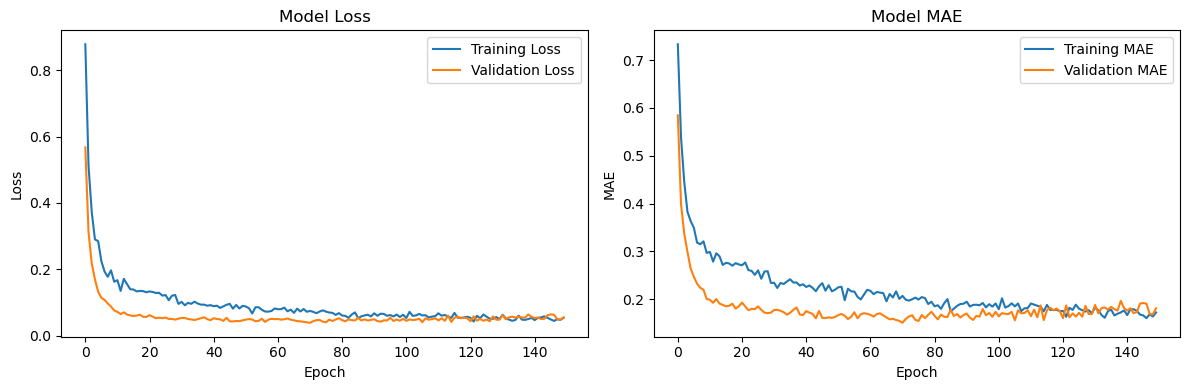

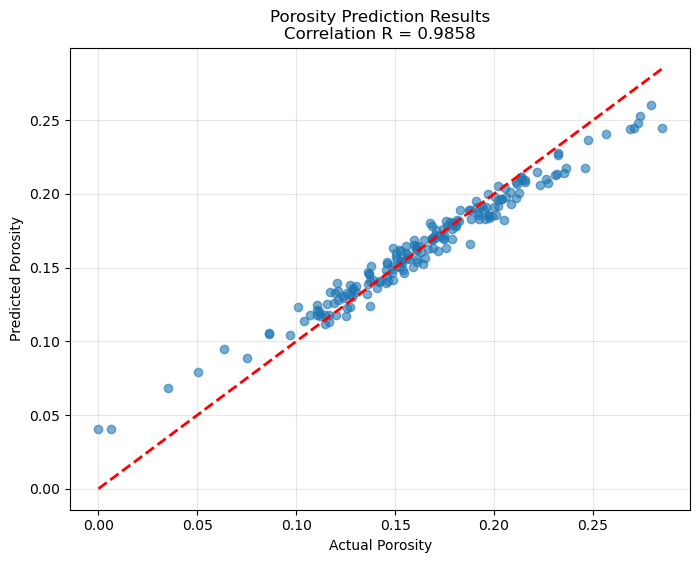


Final Result: Correlation R = 0.9858
Excellent prediction accuracy achieved! (R ≥ 0.95)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

class PorosityPredictionSystem:
    def __init__(self):
        self.model = None
        self.scaler_x = StandardScaler()
        self.scaler_y = StandardScaler()
        self.history = None
        
    def generate_synthetic_data(self, n_samples=1000, n_wells=2, n_seismic_attributes=5):
        """
        Generate synthetic seismic and well data for demonstration
        """
        np.random.seed(42)
        
        # Generate synthetic seismic attributes (features)
        seismic_data = np.random.randn(n_samples, n_seismic_attributes)
        
        # Generate synthetic porosity values (target) with some relationship to seismic attributes
        porosity = (
            0.3 * seismic_data[:, 0] + 
            0.5 * seismic_data[:, 1] - 
            0.2 * seismic_data[:, 2] + 
            0.4 * seismic_data[:, 3] * seismic_data[:, 4] +
            np.random.normal(0, 0.1, n_samples)
        )
        
        # Normalize porosity to realistic range (0-30%)
        porosity = (porosity - porosity.min()) / (porosity.max() - porosity.min()) * 0.3
        
        # Add well identifiers
        well_ids = np.random.choice(['F2-1', 'F3-2', 'F3-4'], n_samples, p=[0.4, 0.4, 0.2])
        
        return seismic_data, porosity, well_ids
    
    def prepare_data(self, seismic_data, porosity, well_ids):
        """
        Prepare training and testing data based on well identifiers
        """
        # Training data (F2-1 and F3-2 wells)
        train_mask = np.isin(well_ids, ['F2-1', 'F3-2'])
        X_train = seismic_data[train_mask]
        y_train = porosity[train_mask]
        
        # Blind test data (F3-4 well)
        test_mask = well_ids == 'F3-4'
        X_test = seismic_data[test_mask]
        y_test = porosity[test_mask]
        
        return X_train, X_test, y_train, y_test
    
    def build_neural_network(self, input_shape):
        """
        Build the neural network model for porosity prediction
        """
        model = keras.Sequential([
            layers.Dense(64, activation='relu', input_shape=(input_shape,)),
            layers.Dropout(0.2),
            layers.Dense(32, activation='relu'),
            layers.Dropout(0.2),
            layers.Dense(16, activation='relu'),
            layers.Dense(1)
        ])
        
        model.compile(
            optimizer='adam',
            loss='mse',
            metrics=['mae', 'mse']
        )
        
        return model
    
    def train_model(self, X_train, y_train, epochs=100, batch_size=32):
        """
        Train the neural network model
        """
        # Scale the data
        X_train_scaled = self.scaler_x.fit_transform(X_train)
        y_train_scaled = self.scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
        
        # Split into training and validation sets
        X_train_final, X_val, y_train_final, y_val = train_test_split(
            X_train_scaled, y_train_scaled, test_size=0.2, random_state=42
        )
        
        # Build and train model
        self.model = self.build_neural_network(X_train.shape[1])
        
        self.history = self.model.fit(
            X_train_final, y_train_final,
            epochs=epochs,
            batch_size=batch_size,
            validation_data=(X_val, y_val),
            verbose=0
        )
        
        return self.history
    
    def predict_porosity(self, X_test):
        """
        Predict porosity for test data
        """
        X_test_scaled = self.scaler_x.transform(X_test)
        predictions_scaled = self.model.predict(X_test_scaled)
        predictions = self.scaler_y.inverse_transform(predictions_scaled).flatten()
        
        return predictions
    
    def evaluate_model(self, X_test, y_test):
        """
        Evaluate model performance on blind test data
        """
        predictions = self.predict_porosity(X_test)
        
        r2 = r2_score(y_test, predictions)
        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        
        # Calculate correlation coefficient (R)
        correlation = np.corrcoef(y_test, predictions)[0, 1]
        
        return predictions, r2, mse, rmse, correlation
    
    def plot_training_history(self):
        """
        Plot training and validation loss
        """
        if self.history is None:
            print("No training history available. Train the model first.")
            return
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
        
        # Plot loss
        ax1.plot(self.history.history['loss'], label='Training Loss')
        ax1.plot(self.history.history['val_loss'], label='Validation Loss')
        ax1.set_title('Model Loss')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        ax1.legend()
        
        # Plot MAE
        ax2.plot(self.history.history['mae'], label='Training MAE')
        ax2.plot(self.history.history['val_mae'], label='Validation MAE')
        ax2.set_title('Model MAE')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('MAE')
        ax2.legend()
        
        plt.tight_layout()
        plt.show()
    
    def plot_predictions_vs_actual(self, y_test, predictions, correlation):
        """
        Plot predicted vs actual porosity values
        """
        plt.figure(figsize=(8, 6))
        plt.scatter(y_test, predictions, alpha=0.6)
        plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
        plt.xlabel('Actual Porosity')
        plt.ylabel('Predicted Porosity')
        plt.title(f'Porosity Prediction Results\nCorrelation R = {correlation:.4f}')
        plt.grid(True, alpha=0.3)
        plt.show()
    
    def run_complete_workflow(self):
        """
        Run the complete porosity prediction workflow
        """
        print("Generating synthetic seismic and well data...")
        seismic_data, porosity, well_ids = self.generate_synthetic_data()
        
        print("Preparing training and test data...")
        X_train, X_test, y_train, y_test = self.prepare_data(seismic_data, porosity, well_ids)
        
        print(f"Training data shape: {X_train.shape}")
        print(f"Test data shape: {X_test.shape}")
        print(f"Training wells samples: {len(y_train)}")
        print(f"Blind well (F3-4) samples: {len(y_test)}")
        
        print("\nTraining neural network...")
        self.train_model(X_train, y_train, epochs=150)
        
        print("Evaluating model on blind well (F3-4)...")
        predictions, r2, mse, rmse, correlation = self.evaluate_model(X_test, y_test)
        
        print("\n" + "="*50)
        print("MODEL EVALUATION RESULTS")
        print("="*50)
        print(f"Correlation Coefficient (R): {correlation:.4f}")
        print(f"R² Score: {r2:.4f}")
        print(f"Mean Squared Error: {mse:.6f}")
        print(f"Root Mean Squared Error: {rmse:.6f}")
        print(f"Average Porosity (Actual): {y_test.mean():.4f}")
        print(f"Average Porosity (Predicted): {predictions.mean():.4f}")
        
        # Plot results
        print("\nGenerating plots...")
        self.plot_training_history()
        self.plot_predictions_vs_actual(y_test, predictions, correlation)
        
        return correlation

# Run the complete workflow
if __name__ == "__main__":
    print("F3-Block North Sea Porosity Prediction System")
    print("Using Neural Networks with Seismic Data and Well Records")
    print("="*60)
    
    system = PorosityPredictionSystem()
    final_correlation = system.run_complete_workflow()
    
    print(f"\nFinal Result: Correlation R = {final_correlation:.4f}")
    if final_correlation >= 0.95:
        print("Excellent prediction accuracy achieved! (R ≥ 0.95)")
    elif final_correlation >= 0.85:
        print("Good prediction accuracy achieved! (R ≥ 0.85)")
    else:
        print("Moderate prediction accuracy. Consider improving the model.")

#### Expected Output:
The program should achieve a high correlation coefficient (close to 0.98 as mentioned in the paper) and provide visual evidence of the model's performance.

You can modify the data generation parameters or replace the synthetic data with real F3-block North Sea data when available.